# Landscape pages in the NARA pension microfilm scans

How many of the 75,804 TIFFs are wider than tall, and is anything else distinctive about them?

Input: `nara_reel_tif_image_dimensions.csv` (from `get_image_dimensions.py`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("nara_reel_tif_image_dimensions.csv")

# Reel and page number are encoded in the URL, e.g. .../M804-1755/M804-1755-0273.tif
# (one URL has a trailing letter, e.g. "-1069m.tif", so allow trailing characters)
parts = df.pageImageURL.str.extract(r"M804-(\d+)/M804-\d+-(\d+)")
df["reel"] = parts[0].astype(int)
df["page"] = parts[1].astype(int)

df["aspect"] = df.width / df.height          # >1 means landscape
df["megapixels"] = df.width * df.height / 1e6
df["orientation"] = "portrait"
df.loc[df.width > df.height, "orientation"] = "landscape"
df.loc[df.width == df.height, "orientation"] = "square"

df = df.sort_values(["reel", "page"]).reset_index(drop=True)
print(len(df), "images,", df.reel.nunique(), "reels,", df.isna().sum().sum(), "missing values")

75804 images, 74 reels, 0 missing values


## 1. How many are landscape?

In [2]:
counts = df.orientation.value_counts()
pd.DataFrame({"images": counts, "percent": (counts / len(df) * 100).round(2)})

,images,percent
orientation,,
portrait,72071,95.08
landscape,3731,4.92
square,2,0.00


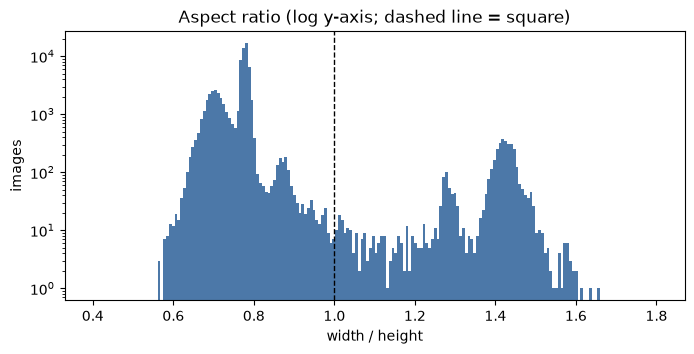

Aspect ratio quartiles by orientation:


,count,mean,std,min,25%,50%,75%,max
orientation,,,,,,,,
landscape,3731.0,1.391,0.099,1.002,1.393,1.419,1.438,3.297
portrait,72071.0,0.758,0.042,0.191,0.727,0.773,0.782,0.997
square,2.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df.aspect, bins=200, range=(0.4, 1.8), color="#4c78a8")
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_xlabel("width / height"); ax.set_ylabel("images"); ax.set_yscale("log")
ax.set_title("Aspect ratio (log y-axis; dashed line = square)")
plt.show()
print("Aspect ratio quartiles by orientation:")
df.groupby("orientation").aspect.describe().round(3)

The distribution is clearly **bimodal**: a big portrait peak around 0.77 and a small, separate landscape peak around 1.4. Landscape images are not just slightly-rotated portraits; they are a distinct kind of page.

## 2. Are they bigger or different in size?

In [4]:
land = df[df.orientation == "landscape"]
port = df[df.orientation == "portrait"]
pd.DataFrame({"portrait": port[["width", "height", "megapixels"]].median(),
              "landscape": land[["width", "height", "megapixels"]].median()}).round(1)

,portrait,landscape
width,3929.0,6393.0
height,5144.0,4489.0
megapixels,20.5,28.7


Landscape scans have ~40% more pixels at the median (28.7 MP vs 20.5 MP). Their long side is ~6,400 px vs ~5,100 px for portrait pages, so the source pages (or camera framing) were physically larger.

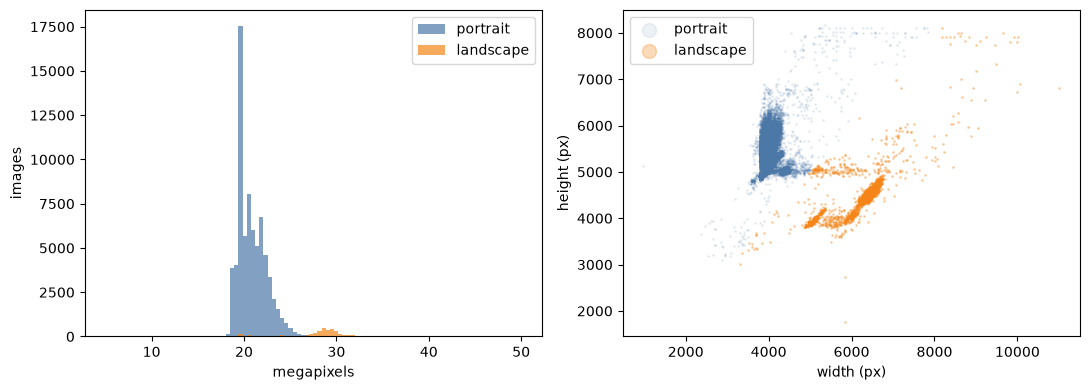

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(port.megapixels, bins=100, range=(5, 50), alpha=.7, label="portrait", color="#4c78a8")
axes[0].hist(land.megapixels, bins=100, range=(5, 50), alpha=.7, label="landscape", color="#f58518")
axes[0].set_xlabel("megapixels"); axes[0].set_ylabel("images"); axes[0].legend()
axes[1].scatter(port.width, port.height, s=1, alpha=.1, label="portrait", color="#4c78a8")
axes[1].scatter(land.width, land.height, s=1, alpha=.3, label="landscape", color="#f58518")
axes[1].set_xlabel("width (px)"); axes[1].set_ylabel("height (px)"); axes[1].legend(markerscale=10)
plt.tight_layout(); plt.show()

## 3. Where do they occur?

count    74.00
mean      4.95
std       1.15
min       3.27
25%       4.17
50%       4.72
75%       5.49
max       7.70
Name: pct_landscape, dtype: float64


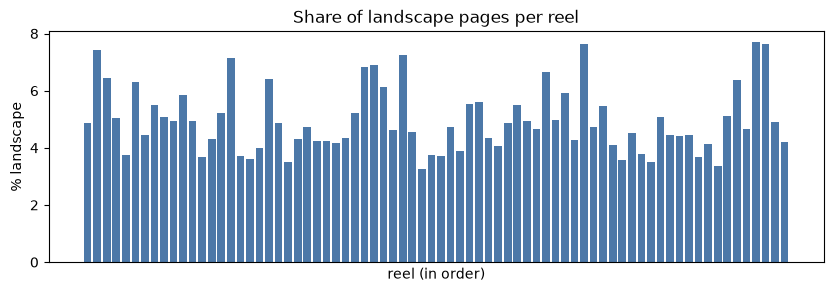

In [6]:
by_reel = df.groupby("reel").apply(lambda g: pd.Series({
    "pages": len(g), "landscape": (g.orientation == "landscape").sum()}), include_groups=False)
by_reel["pct_landscape"] = by_reel.landscape / by_reel.pages * 100
print(by_reel.pct_landscape.describe().round(2))

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(by_reel.index.astype(str), by_reel.pct_landscape, color="#4c78a8")
ax.set_xticks([]); ax.set_xlabel("reel (in order)"); ax.set_ylabel("% landscape")
ax.set_title("Share of landscape pages per reel")
plt.show()

Every reel contains landscape pages, in a narrow 3-8% band (median ~4.7%), so this is not a few odd reels. It is a regular feature of the material.

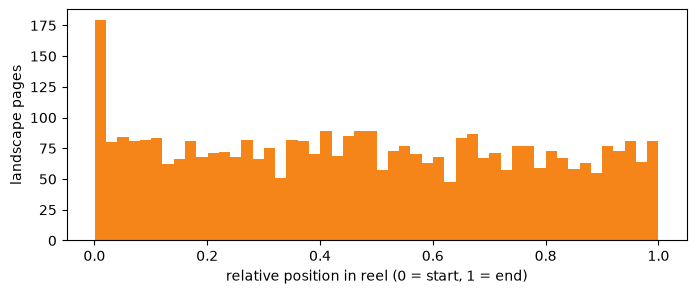

In [7]:
# Position within reel: are they concentrated at the start / end, or spread throughout?
df["pos"] = df.groupby("reel").page.rank(pct=True)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(df[df.orientation == "landscape"].pos, bins=50, color="#f58518")
ax.set_xlabel("relative position in reel (0 = start, 1 = end)"); ax.set_ylabel("landscape pages")
plt.show()

The histogram above is close to flat: landscape pages occur throughout reels, with only a modest excess in the first 10% of a reel.

## 4. Do they occur singly, or in runs?

In [8]:
is_land = df.orientation == "landscape"
# a new "run" starts whenever orientation or reel changes
run_id = ((is_land != is_land.shift()) | (df.reel != df.reel.shift())).cumsum()
run_lengths = df[is_land].groupby(run_id[is_land]).size()
rl = run_lengths.value_counts().sort_index()
pd.DataFrame({"runs": rl, "share_of_runs_%": (rl / rl.sum() * 100).round(1)}).head(8)

,runs,share_of_runs_%
1,2386,81.2
2,403,13.7
3,99,3.4
4,32,1.1
5,10,0.3
6,7,0.2
7,2,0.1
8,1,0.0


81% of landscape runs are a single page sandwiched between portrait pages; only ~5% of runs are 3+ pages long. They are interspersed through the reels, not grouped into separate sections.

## 5. What are they? A visual check

Five randomly chosen landscape images (downscaled), from reels 1732, 1992, 1934, 1794, 1770:

![landscape sample](landscape_sample.png)

Three of the five are **pension file jackets/covers**: a ruled card with the state, the veteran's name and a claim number (`S.` / `R.`) in the header. The other two are wide documents (a ledger-style table and a certificate that was scanned sideways or is simply wide).

## 6. Hypothesis: landscape covers mark the start of each pension file

If the jackets begin each file, the gaps between consecutive landscape pages within a reel should look like file lengths (tens of pages), with a long tail.

count    3657.0
mean       20.2
std        20.5
min         1.0
25%         3.0
50%        16.0
75%        29.0
max       199.0
Name: page, dtype: float64


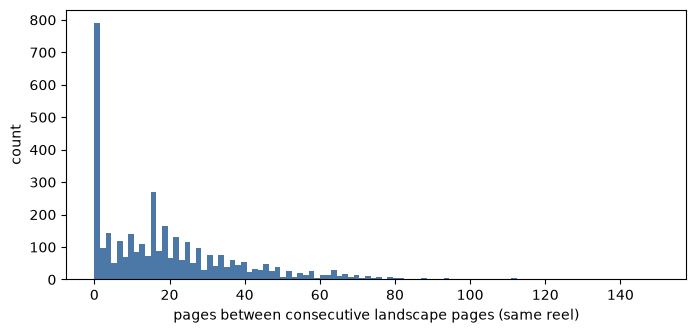

In [9]:
gaps = df[is_land].groupby("reel").page.diff().dropna()
print(gaps.describe().round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(gaps, bins=100, range=(0, 150), color="#4c78a8")
ax.set_xlabel("pages between consecutive landscape pages (same reel)"); ax.set_ylabel("count")
plt.show()

In [10]:
# Sub-population: landscape pages with the "typical" cover-like size
cover_like = land[(land.width.between(6000, 6700)) & (land.height.between(4300, 4700))]
print(f"{len(cover_like):,} of {len(land):,} landscape pages ({len(cover_like)/len(land):.0%}) are in the 6000-6700 x 4300-4700 px band")
land.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).rename("images").to_frame()

2,391 of 3,731 landscape pages (64%) are in the 6000-6700 x 4300-4700 px band


images
width height        
6425  4457        24
6441  4473        22
6377  4473        20
6425  4489        20
6409  4489        20
6489  4569        19
6457  4489        18
6393  4521        18
      4505        18
      4489        18

**Reading the result:** the median gap is 16 pages and ~68% of gaps are 4-60 pages, which is consistent with landscape pages marking file boundaries. But ~26% of gaps are 3 pages or fewer, and a few exceed 100, so it is *not* a clean one-cover-per-file signal. Some landscape pages are wide interior documents (like the ledger in the sample), and some files probably have no landscape cover, or several. Also, 64% of landscape pages fall in a tight 6000-6700 x 4300-4700 px band, which probably corresponds to the jackets (consistent with ~3 of 5 in the visual sample). Treat the size band as a candidate cover detector, to be verified by looking at images.

## 7. Other oddities

In [11]:
odd = df[(df.aspect > 2) | (df.aspect < 0.5) | (df.megapixels < 8) | (df.megapixels > 50)]
print(len(odd), "extreme images (aspect >2 or <0.5, <8 MP, >50 MP)")
odd.sort_values("megapixels")[["pageImageURL", "width", "height", "megapixels"]].head(10)

77 extreme images (aspect >2 or <0.5, <8 MP, >50 MP)


,pageImageURL,width,height,megapixels
72293,https://catalog.archives.gov/medialz/dc-metro/...,979,5136,5.028144
27091,https://catalog.archives.gov/medialz/dc-metro/...,5833,1769,10.318577
26829,https://catalog.archives.gov/medialz/dc-metro/...,5849,2729,15.961921
67389,https://catalog.archives.gov/medialz/dc-metro/...,6280,8007,50.283960
8789,https://catalog.archives.gov/medialz/dc-metro/...,8408,6024,50.649792
66330,https://catalog.archives.gov/medialz/dc-metro/...,6280,8099,50.861720
33867,https://catalog.archives.gov/medialz/dc-metro/...,8448,6036,50.992128
49390,https://catalog.archives.gov/medialz/dc-metro/...,8874,5777,51.265098
62526,https://catalog.archives.gov/medialz/dc-metro/...,6371,8099,51.598729
4801,https://catalog.archives.gov/medialz/dc-metro/...,6477,8001,51.822477


## Summary

- **3,731 of 75,804 images (4.9%) are landscape**; 2 are exactly square; the rest are portrait.
- The aspect-ratio distribution is **bimodal** (portrait peak ~0.77, landscape peak ~1.42), so landscape is a distinct page type.
- They are **larger** (median 28.7 MP vs 20.5 MP), present in **all 74 reels** at a steady 3-8% rate, spread through each reel, and usually **isolated** single pages (81% of runs).
- A visual sample shows many are **pension file jackets** (state, name, S./R. number). The gaps between landscape pages (median 16 pages) are consistent with them marking file starts, but not cleanly: some are interior wide documents, so this is a useful hint and not a reliable boundary on its own.
- Other oddities: ~77 extreme images (very small, very large >50 MP, or very wide/narrow), plus one URL with a trailing letter (`-1069m.tif`).
- **Next step if this is for splitting reels:** combine orientation with the 6000-6700 x 4300-4700 size band as a candidate-cover feature, then check against a hand-labelled sample.